# Tugas 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas
**HASAN/2802529203:** Deep Learning — Sesi 05 (Advanced CNNs & Transfer Learning)




| Kode | Kondisi | Augmentasi |
|---|---|---|
| B1 | ResNet-18 from scratch (`weights=None`) | ya |
| B2 | Feature extraction (backbone beku, latih `fc` saja) | ya |
| B3 | Progressive fine-tuning (`layer4` + `fc`, differential LR) | ya |
| B4 | Uji kontrol augmentasi pada konfigurasi B3: `B4-noaug` vs `B3` (= B4-aug) | tidak / ya |
| B5 | Konfigurasi terbaik (B2/B3) pada EfficientNet-B0 dan MobileNetV3-Small | ya |

## 0. Setup & konfigurasi

In [1]:
import os, sys, time, json, copy, random, platform, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# ---------------- Konfigurasi eksperimen ----------------
SEED         = 42
DATA_ROOT    = "./data"
OUT_DIR      = Path("./outputs")
FIG_DIR      = OUT_DIR / "figures"
BATCH_SIZE   = 32
MAX_EPOCHS   = 30          # batas atas; early stopping biasanya berhenti lebih awal
PATIENCE     = 5           # patience early stopping (protokol: 3–5)
MIN_DELTA    = 1e-4        # perbaikan minimum val loss agar dianggap "membaik"
WEIGHT_DECAY = 1e-2
NUM_WORKERS  = 2
IMG_SIZE     = 224
RUN_B5       = True        # bonus: arsitektur pembanding

# 5 ras kucing + 5 ras anjing (sengaja memuat pasangan yang mirip: Birman–Ragdoll,
# American Pit Bull Terrier–Staffordshire Bull Terrier, Beagle–Basset Hound)
SELECTED_CLASSES = [
    "abyssinian", "bengal", "birman", "ragdoll", "siamese",                     # kucing
    "american_pit_bull_terrier", "staffordshire_bull_terrier", "beagle",
    "basset_hound", "samoyed",                                                  # anjing
]
NUM_CLASSES = len(SELECTED_CLASSES)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

OUT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"   # mixed precision hanya di GPU

def set_seed(seed: int = SEED):
    # Reproduksibilitas: Python, NumPy, PyTorch (CPU & CUDA), cuDNN deterministik
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

ENV_INFO = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "seed": SEED, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "weight_decay": WEIGHT_DECAY, "optimizer": "AdamW", "loss": "CrossEntropyLoss", "amp": USE_AMP,
}
print(json.dumps(ENV_INFO, indent=2))

{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "device": "cuda",
  "gpu": "Tesla T4",
  "seed": 42,
  "batch_size": 32,
  "max_epochs": 30,
  "patience": 5,
  "weight_decay": 0.01,
  "optimizer": "AdamW",
  "loss": "CrossEntropyLoss",
  "amp": true
}


## 1. Data: subset 10 kelas Oxford-IIIT Pet + split stratified 70/15/15
Split `trainval` dan `test` bawaan digabung terlebih dahulu, lalu dipecah ulang secara **stratified** (seed 42).
Nama kelas diambil dari nama berkas (mis. `birman_12.jpg` → `birman`). Daftar berkas per split disimpan ke
`outputs/split_manifest.csv` dan dicek tidak ada irisan (mencegah *data leakage*).

In [ ]:
ds_trainval = datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", download=True)
ds_test     = datasets.OxfordIIITPet(DATA_ROOT, split="test",     target_types="category", download=True)

all_paths = list(ds_trainval._images) + list(ds_test._images)
breed_of  = lambda p: Path(p).stem.rsplit("_", 1)[0].lower()

cls_to_idx = {c: i for i, c in enumerate(SELECTED_CLASSES)}
paths  = [str(p) for p in all_paths if breed_of(p) in cls_to_idx]
labels = [cls_to_idx[breed_of(p)] for p in paths]
CLASS_NAMES = [c.replace("_", " ").title() for c in SELECTED_CLASSES]

idx = np.arange(len(paths))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50,
                                      stratify=[labels[i] for i in idx_tmp], random_state=SEED)

assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) \
       and not (set(idx_val) & set(idx_test)), "Data leakage: split beririsan!"

SPLITS = {
    "train": ([paths[i] for i in idx_train], [labels[i] for i in idx_train]),
    "val":   ([paths[i] for i in idx_val],   [labels[i] for i in idx_val]),
    "test":  ([paths[i] for i in idx_test],  [labels[i] for i in idx_test]),
}
manifest = pd.concat([pd.DataFrame({"path": p, "label": y, "class": [CLASS_NAMES[k] for k in y], "split": s})
                      for s, (p, y) in SPLITS.items()], ignore_index=True)
manifest.to_csv(OUT_DIR / "split_manifest.csv", index=False)

print(f"Total citra subset: {len(paths)}")
display(manifest.pivot_table(index="class", columns="split", values="path", aggfunc="count")
        [["train", "val", "test"]].assign(total=lambda d: d.sum(axis=1)))

100%|██████████| 792M/792M [00:38<00:00, 20.5MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.16MB/s]


Total citra subset: 1986


split,train,val,test,total
class,,,,
Abyssinian,139,29,30,198
American Pit Bull Terrier,140,30,30,200
Basset Hound,140,30,30,200
Beagle,140,30,30,200
Bengal,140,30,30,200
Birman,140,30,30,200
Ragdoll,140,30,30,200
Samoyed,140,30,30,200
Siamese,139,30,30,199


### Pipeline transformasi
Augmentasi **hanya** dipasang pada data latih; validasi/uji selalu deterministik
(`Resize(256) → CenterCrop(224) → Normalize`, setara dengan `ResNet18_Weights.IMAGENET1K_V1.transforms()`).

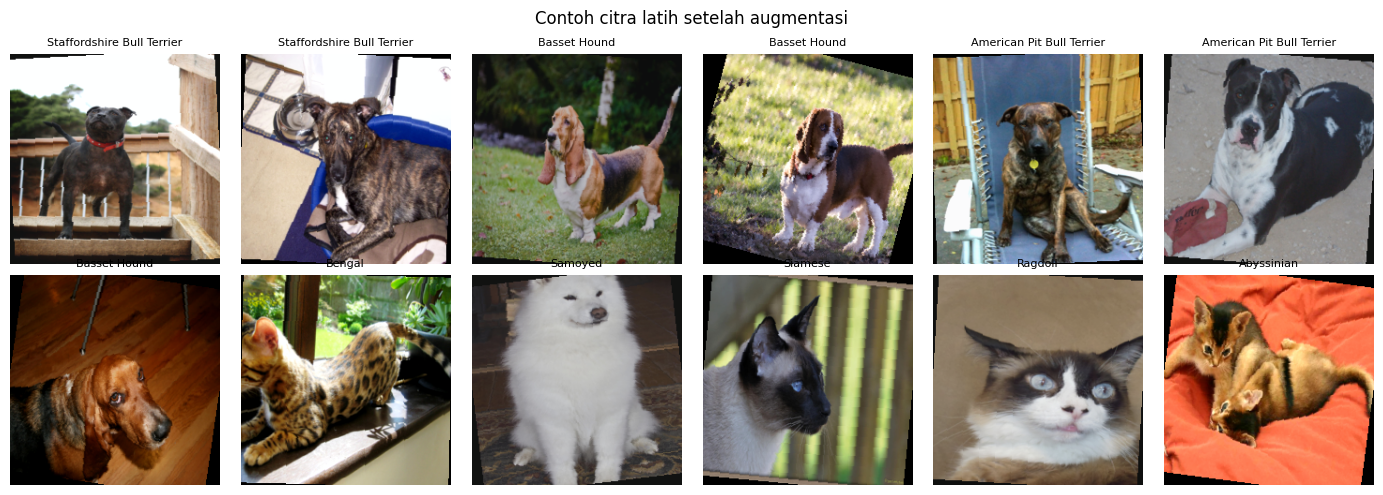

In [ ]:
train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([          
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_tf_noaug = eval_tf

class PetSubset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(split, transform, shuffle):
    p, y = SPLITS[split]
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(PetSubset(p, y, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                      worker_init_fn=seed_worker, generator=g)

val_loader  = make_loader("val",  eval_tf, shuffle=False)
test_loader = make_loader("test", eval_tf, shuffle=False)

# Pratinjau beberapa citra latih teraugmentasi
def denorm(t):
    return (t.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1)
xb, yb = next(iter(make_loader("train", train_tf_aug, shuffle=True)))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(x)); ax.set_title(CLASS_NAMES[y], fontsize=8); ax.axis("off")
plt.suptitle("Contoh citra latih setelah augmentasi"); plt.tight_layout()
plt.savefig(FIG_DIR / "augmented_samples.png", dpi=120); plt.show()

## 2. Pembangun model (B1/B2/B3/B5)
Catatan penting implementasi pembekuan: `requires_grad=False` **tidak** menghentikan BatchNorm memperbarui
*running mean/var* saat `model.train()`. Agar backbone benar-benar beku (B2) dan blok `layer1–3` tetap utuh (B3),
lapisan BatchNorm yang seluruh parameternya beku dipaksa ke mode `eval()` di setiap epoch (`freeze_frozen_bn`).

In [4]:
W = models  # alias singkat

def freeze_all(m):
    for p in m.parameters(): p.requires_grad = False

def unfreeze(m):
    for p in m.parameters(): p.requires_grad = True

def build_resnet18(strategy):
    if strategy == "scratch":
        m = models.resnet18(weights=None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        groups = [{"name": "all", "params": list(m.parameters()), "lr": 1e-3}]
        return m, groups
    m = models.resnet18(weights=W.ResNet18_Weights.IMAGENET1K_V1)
    freeze_all(m)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)        # head baru -> trainable
    if strategy == "feature":
        groups = [{"name": "fc", "params": list(m.fc.parameters()), "lr": 1e-3}]
    elif strategy == "finetune":
        unfreeze(m.layer4)
        groups = [{"name": "layer4", "params": list(m.layer4.parameters()), "lr": 1e-4},
                  {"name": "fc",     "params": list(m.fc.parameters()),     "lr": 1e-3}]
    else:
        raise ValueError(strategy)
    return m, groups

def build_efficientnet_b0(strategy):
    m = models.efficientnet_b0(weights=W.EfficientNet_B0_Weights.IMAGENET1K_V1)
    freeze_all(m)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    if strategy == "feature":
        return m, [{"name": "head", "params": list(m.classifier.parameters()), "lr": 1e-3}]
    tail = m.features[7:]          # stage MBConv terakhir + conv 1x1 akhir (analog layer4)
    unfreeze(tail)
    return m, [{"name": "features[7:]", "params": list(tail.parameters()), "lr": 1e-4},
               {"name": "head",         "params": list(m.classifier.parameters()), "lr": 1e-3}]

def build_mobilenet_v3_small(strategy):
    m = models.mobilenet_v3_small(weights=W.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
    freeze_all(m)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM_CLASSES)
    if strategy == "feature":
        return m, [{"name": "head", "params": list(m.classifier[3].parameters()), "lr": 1e-3}]
    tail = m.features[9:]          # blok 96-channel terakhir + conv 1x1 akhir (analog layer4)
    unfreeze(tail); unfreeze(m.classifier)
    return m, [{"name": "features[9:]", "params": list(tail.parameters()), "lr": 1e-4},
               {"name": "head",         "params": list(m.classifier.parameters()), "lr": 1e-3}]

def count_params(m):
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    total = sum(p.numel() for p in m.parameters())
    return trainable, total

def freeze_frozen_bn(model):
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            ps = list(mod.parameters())
            if ps and not any(p.requires_grad for p in ps):
                mod.eval()

# Verifikasi jumlah parameter trainable sebelum training (tips di soal: B2 = 5.130)
for s in ["scratch", "feature", "finetune"]:
    m, _ = build_resnet18(s); t, tot = count_params(m)
    print(f"ResNet-18 [{s:8s}] trainable = {t:>12,} / {tot:,}")
_m, _ = build_resnet18("feature"); assert count_params(_m)[0] == 512 * NUM_CLASSES + NUM_CLASSES
del _m

ResNet-18 [scratch ] trainable =   11,181,642 / 11,181,642
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


ResNet-18 [feature ] trainable =        5,130 / 11,181,642
ResNet-18 [finetune] trainable =    8,398,858 / 11,181,642


## 3. Loop pelatihan, early stopping, evaluasi, dan pencatatan log

In [ ]:
EPOCH_LOG, SUMMARY, MODELS, PREDS = [], [], {}, {}

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    if train: freeze_frozen_bn(model)
    tot_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x); loss = criterion(out, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        tot_loss += loss.item() * x.size(0)
        correct  += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot_loss / n, correct / n

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE))
        ps.append(F.softmax(out.float(), 1).cpu()); ys.append(y)
    probs = torch.cat(ps).numpy(); y_true = torch.cat(ys).numpy()
    return y_true, probs.argmax(1), probs

@torch.no_grad()
def latency_ms_per_img(model, n_iter=20):
    model.eval(); x = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    for _ in range(5): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n_iter): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (n_iter * BATCH_SIZE) * 1000

def save_logs():
    pd.DataFrame(EPOCH_LOG).to_csv(OUT_DIR / "metrics_per_epoch.csv", index=False)
    pd.DataFrame(SUMMARY).to_csv(OUT_DIR / "summary.csv", index=False)
    with open(OUT_DIR / "results.json", "w") as f:
        json.dump({"env": ENV_INFO, "classes": CLASS_NAMES,
                   "split_sizes": {k: len(v[0]) for k, v in SPLITS.items()},
                   "summary": SUMMARY, "epoch_log": EPOCH_LOG}, f, indent=2, default=float)

def run_experiment(code, arch, strategy, builder, augment=True, note=""):
    print(f"\n{'='*70}\n{code} | {arch} | strategy={strategy} | augment={augment}\n{'='*70}")
    set_seed(SEED)
    model, groups = builder(strategy)
    model.to(DEVICE)
    trainable, total = count_params(model)
    assert trainable == sum(p.numel() for g in groups for p in g["params"]), "param group tidak cocok dg requires_grad"
    lr_desc = ", ".join(f"{g['name']}={g['lr']:g}" for g in groups)
    print(f"Trainable params: {trainable:,} / {total:,} | LR: {lr_desc}")

    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    scaler    = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    criterion = nn.CrossEntropyLoss()
    train_loader = make_loader("train", train_tf_aug if augment else train_tf_noaug, shuffle=True)

    best_loss, best_state, best_epoch, wait, hist = float("inf"), None, 0, 0, []
    t_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        ep_time = time.perf_counter() - t0
        row = {"experiment": code, "arch": arch, "strategy": strategy, "augment": augment, "epoch": epoch,
               "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss, "val_acc": va_acc,
               "epoch_time_s": ep_time,
               **{f"lr_{g['name']}": g["lr"] for g in optimizer.param_groups}}
        hist.append(row); EPOCH_LOG.append(row)
        improved = va_loss < best_loss - MIN_DELTA
        if improved:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        print(f"ep {epoch:02d} | train {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{va_acc:.3f} "
              f"| {ep_time:5.1f}s {'*' if improved else ''}")
        if wait >= PATIENCE:
            print(f"Early stopping: val loss tidak membaik selama {PATIENCE} epoch."); break
    train_time = time.perf_counter() - t_start
    model.load_state_dict(best_state)          # kembalikan bobot terbaik (val loss terendah)

    y_true, y_pred, probs = predict(model, test_loader)
    best_row = hist[best_epoch - 1]
    summary = {
        "experiment": code, "arch": arch, "strategy": strategy, "augment": augment,
        "trainable_params": trainable, "total_params": total, "lr": lr_desc,
        "epochs_run": len(hist), "best_epoch": best_epoch, "train_time_s": round(train_time, 1),
        "train_acc_best": best_row["train_acc"], "val_acc": best_row["val_acc"], "val_loss": best_row["val_loss"],
        "gap_train_val_acc": best_row["train_acc"] - best_row["val_acc"],
        "test_acc": accuracy_score(y_true, y_pred),
        "test_macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "latency_ms_per_img": latency_ms_per_img(model), "note": note,
    }
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items()})
    SUMMARY.append(summary); PREDS[code] = (y_true, y_pred, probs)
    MODELS[code] = model.cpu()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    save_logs()                              
    return summary

## 4. Eksperimen B1–B3

In [6]:
run_experiment("B1", "resnet18", "scratch", build_resnet18, augment=True, note="baseline from scratch");


B1 | resnet18 | strategy=scratch | augment=True
Trainable params: 11,181,642 / 11,181,642 | LR: all=0.001
ep 01 | train 2.3337/0.169 | val 2.1710/0.215 |  18.3s *
ep 02 | train 2.0817/0.237 | val 2.1059/0.215 |  16.1s *
ep 03 | train 1.9744/0.281 | val 2.0496/0.265 |  14.1s *
ep 04 | train 1.8945/0.289 | val 1.9378/0.289 |  14.0s *
ep 05 | train 1.8188/0.332 | val 1.7716/0.359 |  14.0s *
ep 06 | train 1.7477/0.359 | val 1.8444/0.352 |  14.2s 
ep 07 | train 1.6900/0.362 | val 1.6802/0.376 |  14.3s *
ep 08 | train 1.6337/0.389 | val 1.6753/0.389 |  14.0s *
ep 09 | train 1.6296/0.400 | val 2.0416/0.329 |  13.9s 
ep 10 | train 1.5282/0.428 | val 1.6373/0.419 |  14.1s *
ep 11 | train 1.4618/0.468 | val 1.5866/0.426 |  13.9s *
ep 12 | train 1.5063/0.473 | val 1.5918/0.436 |  14.1s 
ep 13 | train 1.3926/0.494 | val 1.5640/0.470 |  13.9s *
ep 14 | train 1.3744/0.504 | val 1.6979/0.413 |  13.9s 
ep 15 | train 1.2922/0.514 | val 1.5912/0.436 |  14.0s 
ep 16 | train 1.2303/0.537 | val 1.6367/0.3

In [7]:
run_experiment("B2", "resnet18", "feature", build_resnet18, augment=True, note="backbone frozen, train fc only");


B2 | resnet18 | strategy=feature | augment=True
Trainable params: 5,130 / 11,181,642 | LR: fc=0.001
ep 01 | train 1.4152/0.564 | val 0.7629/0.745 |  13.8s *
ep 02 | train 0.6314/0.819 | val 0.5091/0.812 |  13.6s *
ep 03 | train 0.4951/0.843 | val 0.4889/0.802 |  13.8s *
ep 04 | train 0.4129/0.877 | val 0.4211/0.849 |  13.9s *
ep 05 | train 0.3762/0.885 | val 0.3727/0.866 |  13.8s *
ep 06 | train 0.3347/0.893 | val 0.3721/0.859 |  14.1s *
ep 07 | train 0.3319/0.881 | val 0.3508/0.872 |  14.0s *
ep 08 | train 0.3038/0.904 | val 0.3429/0.869 |  14.1s *
ep 09 | train 0.2781/0.914 | val 0.3749/0.839 |  13.9s 
ep 10 | train 0.2826/0.905 | val 0.3851/0.839 |  13.9s 
ep 11 | train 0.2675/0.907 | val 0.3655/0.846 |  13.7s 
ep 12 | train 0.2749/0.907 | val 0.3636/0.862 |  13.8s 
ep 13 | train 0.2506/0.922 | val 0.3660/0.836 |  13.7s 
Early stopping: val loss tidak membaik selama 5 epoch.
{'experiment': 'B2', 'arch': 'resnet18', 'strategy': 'feature', 'augment': True, 'trainable_params': 5130, '

In [8]:
run_experiment("B3", "resnet18", "finetune", build_resnet18, augment=True, note="unfreeze layer4+fc, differential LR; = B4-aug");


B3 | resnet18 | strategy=finetune | augment=True
Trainable params: 8,398,858 / 11,181,642 | LR: layer4=0.0001, fc=0.001
ep 01 | train 0.8804/0.709 | val 0.3351/0.856 |  13.4s *
ep 02 | train 0.3056/0.896 | val 0.4000/0.839 |  13.6s 
ep 03 | train 0.2119/0.930 | val 0.2800/0.883 |  13.8s *
ep 04 | train 0.1372/0.954 | val 0.3488/0.872 |  14.0s 
ep 05 | train 0.0890/0.976 | val 0.3043/0.886 |  13.7s 
ep 06 | train 0.0507/0.989 | val 0.3267/0.883 |  13.8s 
ep 07 | train 0.0462/0.991 | val 0.3740/0.879 |  13.2s 
ep 08 | train 0.0349/0.990 | val 0.3053/0.893 |  13.4s 
Early stopping: val loss tidak membaik selama 5 epoch.
{'experiment': 'B3', 'arch': 'resnet18', 'strategy': 'finetune', 'augment': True, 'trainable_params': 8398858, 'total_params': 11181642, 'lr': 'layer4=0.0001, fc=0.001', 'epochs_run': 8, 'best_epoch': 3, 'train_time_s': 109.0, 'train_acc_best': 0.9302, 'val_acc': 0.8826, 'val_loss': 0.28, 'gap_train_val_acc': 0.0477, 'test_acc': 0.9161, 'test_macro_f1': 0.9154, 'latency_m

## 5. B4 — Uji kontrol data augmentation (pada konfigurasi B3)
Skenario **dengan** augmentasi sudah dijalankan sebagai B3 (konfigurasi identik, seed sama), sehingga di sini hanya
dijalankan skenario **tanpa** augmentasi (`Resize/Crop + Normalize`).

In [9]:
run_experiment("B4-noaug", "resnet18", "finetune", build_resnet18, augment=False, note="B3 tanpa augmentasi");


B4-noaug | resnet18 | strategy=finetune | augment=False
Trainable params: 8,398,858 / 11,181,642 | LR: layer4=0.0001, fc=0.001
ep 01 | train 0.7938/0.737 | val 0.3188/0.869 |   9.1s *
ep 02 | train 0.1627/0.962 | val 0.3209/0.879 |   9.1s 
ep 03 | train 0.0629/0.992 | val 0.3187/0.893 |   9.8s 
ep 04 | train 0.0228/1.000 | val 0.3099/0.889 |   9.7s *
ep 05 | train 0.0119/1.000 | val 0.2994/0.893 |   8.6s *
ep 06 | train 0.0070/1.000 | val 0.3063/0.896 |   9.8s 
ep 07 | train 0.0057/1.000 | val 0.3088/0.886 |   9.8s 
ep 08 | train 0.0038/1.000 | val 0.3081/0.889 |   8.6s 
ep 09 | train 0.0033/1.000 | val 0.3007/0.889 |   9.7s 
ep 10 | train 0.0029/1.000 | val 0.3046/0.896 |  11.2s 
Early stopping: val loss tidak membaik selama 5 epoch.
{'experiment': 'B4-noaug', 'arch': 'resnet18', 'strategy': 'finetune', 'augment': False, 'trainable_params': 8398858, 'total_params': 11181642, 'lr': 'layer4=0.0001, fc=0.001', 'epochs_run': 10, 'best_epoch': 5, 'train_time_s': 95.5, 'train_acc_best': 1.

## 6. B5 (Bonus) — Arsitektur pembanding berorientasi efisiensi
Strategi terbaik antara B2 dan B3 dipilih **otomatis berdasarkan akurasi validasi** (bukan test, untuk menghindari
seleksi model berdasarkan data uji), lalu diterapkan pada EfficientNet-B0 dan MobileNetV3-Small.

In [10]:
_s = {r["experiment"]: r for r in SUMMARY}
BEST_STRATEGY = "finetune" if _s["B3"]["val_acc"] >= _s["B2"]["val_acc"] else "feature"
print("Strategi terbaik (berdasar val acc):", BEST_STRATEGY)
if RUN_B5:
    run_experiment("B5-EffNetB0", "efficientnet_b0", BEST_STRATEGY, build_efficientnet_b0, augment=True)
    run_experiment("B5-MobileNetV3S", "mobilenet_v3_small", BEST_STRATEGY, build_mobilenet_v3_small, augment=True)

Strategi terbaik (berdasar val acc): finetune

B5-EffNetB0 | efficientnet_b0 | strategy=finetune | augment=True
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 183MB/s]

Trainable params: 1,142,202 / 4,020,358 | LR: features[7:]=0.0001, head=0.001


ep 01 | train 1.1444/0.691 | val 0.3856/0.876 |  18.4s *
ep 02 | train 0.3946/0.879 | val 0.2683/0.896 |  14.2s *
ep 03 | train 0.3050/0.899 | val 0.2188/0.916 |  14.5s *
ep 04 | train 0.2310/0.922 | val 0.2354/0.919 |  14.3s 
ep 05 | train 0.2005/0.933 | val 0.2121/0.926 |  14.1s *
ep 06 | train 0.1671/0.945 | val 0.2023/0.919 |  14.8s *
ep 07 | train 0.1417/0.956 | val 0.2202/0.916 |  14.2s 
ep 08 | train 0.1254/0.957 | val 0.2134/0.916 |  14.1s 
ep 09 | train 0.1119/0.965 | val 0.2277/0.906 |  22.6s 
ep 10 | train 0.1062/0.968 | val 0.2139/0.919 |  14.3s 
ep 11 | train 0.0999/0.969 | val 0.2066/0.919 |  14.4s 
Early stopping: val loss tidak membaik selama 5 epoch.
{'experiment': 'B5-EffNetB0', 'arch': 'efficientnet_b0', 'strategy': 'finetune', 'augment': True, 'trainable_params': 1142202, 'total_params': 4020358, 'lr': 'features[7:]=0.0001, head=0.001', 'epochs_run': 11, 'best_epoch': 6, 'train_time_s': 170.1, 'train_acc_best': 0.9446, 'val_acc': 0.9195, 'val_loss': 0.2023, 'gap_tra

100%|██████████| 9.83M/9.83M [00:00<00:00, 198MB/s]

Trainable params: 1,337,586 / 1,528,106 | LR: features[9:]=0.0001, head=0.001


ep 01 | train 1.0401/0.627 | val 0.4084/0.842 |  15.2s *
ep 02 | train 0.4392/0.838 | val 0.4570/0.832 |  14.1s 
ep 03 | train 0.3876/0.847 | val 0.4026/0.836 |  14.3s *
ep 04 | train 0.2703/0.901 | val 0.3908/0.859 |  14.7s *
ep 05 | train 0.1856/0.934 | val 0.3508/0.866 |  14.1s *
ep 06 | train 0.1501/0.945 | val 0.4127/0.869 |  14.5s 
ep 07 | train 0.1182/0.953 | val 0.3561/0.899 |  13.9s 
ep 08 | train 0.0909/0.974 | val 0.3777/0.872 |  14.1s 
ep 09 | train 0.0838/0.973 | val 0.5207/0.839 |  14.1s 
ep 10 | train 0.0930/0.967 | val 0.4526/0.883 |  13.9s 
Early stopping: val loss tidak membaik selama 5 epoch.
{'experiment': 'B5-MobileNetV3S', 'arch': 'mobilenet_v3_small', 'strategy': 'finetune', 'augment': True, 'trainable_params': 1337586, 'total_params': 1528106, 'lr': 'features[9:]=0.0001, head=0.001', 'epochs_run': 10, 'best_epoch': 5, 'train_time_s': 143.1, 'train_acc_best': 0.9338, 'val_acc': 0.8658, 'val_loss': 0.3508, 'gap_train_val_acc': 0.068, 'test_acc': 0.896, 'test_macro

## 7. C1 — Tabel konsolidasi & kurva pembelajaran

In [ ]:
summary_df = pd.DataFrame(SUMMARY)
show_cols = ["experiment", "arch", "strategy", "augment", "trainable_params", "lr", "best_epoch", "epochs_run",
             "train_time_s", "train_acc_best", "val_acc", "gap_train_val_acc", "test_acc", "test_macro_f1",
             "latency_ms_per_img"]
table = summary_df[show_cols].copy()
display(table.style.format({c: "{:.4f}" for c in ["train_acc_best", "val_acc", "gap_train_val_acc",
                                                  "test_acc", "test_macro_f1"]} |
                           {"trainable_params": "{:,}", "latency_ms_per_img": "{:.2f}"}))

md_tbl = table.copy()
for c in ["train_acc_best", "val_acc", "gap_train_val_acc", "test_acc", "test_macro_f1"]:
    md_tbl[c] = md_tbl[c].map(lambda v: f"{v:.4f}")
md_tbl["trainable_params"] = md_tbl["trainable_params"].map(lambda v: f"{v:,}")
md_tbl["latency_ms_per_img"] = md_tbl["latency_ms_per_img"].map(lambda v: f"{v:.2f}")
try:
    md_text = md_tbl.to_markdown(index=False)
except ImportError:
    md_text = md_tbl.to_string(index=False)
(OUT_DIR / "summary_table.md").write_text(md_text)
print(md_text)

,experiment,arch,strategy,augment,trainable_params,lr,best_epoch,epochs_run,train_time_s,train_acc_best,val_acc,gap_train_val_acc,test_acc,test_macro_f1,latency_ms_per_img
0,B1,resnet18,scratch,True,"11,181,642",all=0.001,17,22,316.000000,0.5568,0.4866,0.0703,0.4396,0.4160,0.95
1,B2,resnet18,feature,True,"5,130",fc=0.001,8,13,180.300000,0.9043,0.8691,0.0352,0.8725,0.8706,0.94
2,B3,resnet18,finetune,True,"8,398,858","layer4=0.0001, fc=0.001",3,8,109.000000,0.9302,0.8826,0.0477,0.9161,0.9154,0.95
3,B4-noaug,resnet18,finetune,False,"8,398,858","layer4=0.0001, fc=0.001",5,10,95.500000,1.0000,0.8926,0.1074,0.9228,0.9213,0.96
4,B5-EffNetB0,efficientnet_b0,finetune,True,"1,142,202","features[7:]=0.0001, head=0.001",6,11,170.100000,0.9446,0.9195,0.0251,0.9295,0.9291,1.22
5,B5-MobileNetV3S,mobilenet_v3_small,finetune,True,"1,337,586","features[9:]=0.0001, head=0.001",5,10,143.100000,0.9338,0.8658,0.0680,0.8960,0.8958,0.34


| experiment      | arch               | strategy   | augment   | trainable_params   | lr                              |   best_epoch |   epochs_run |   train_time_s |   train_acc_best |   val_acc |   gap_train_val_acc |   test_acc |   test_macro_f1 |   latency_ms_per_img |
|:----------------|:-------------------|:-----------|:----------|:-------------------|:--------------------------------|-------------:|-------------:|---------------:|-----------------:|----------:|--------------------:|-----------:|----------------:|---------------------:|
| B1              | resnet18           | scratch    | True      | 11,181,642         | all=0.001                       |           17 |           22 |          316   |           0.5568 |    0.4866 |              0.0703 |     0.4396 |          0.416  |                 0.95 |
| B2              | resnet18           | feature    | True      | 5,130              | fc=0.001                        |            8 |           13 |          180.3 |        

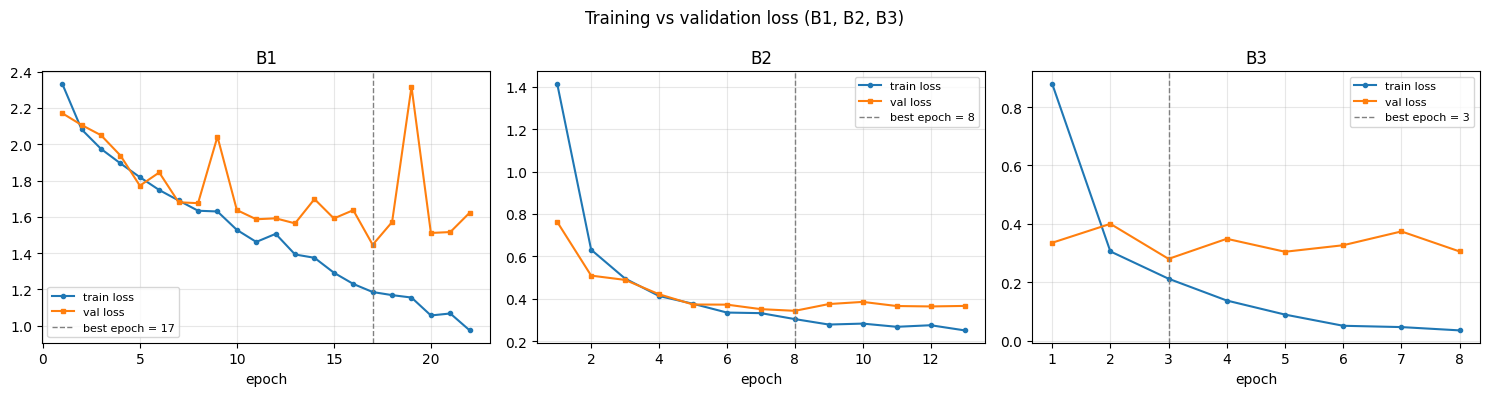

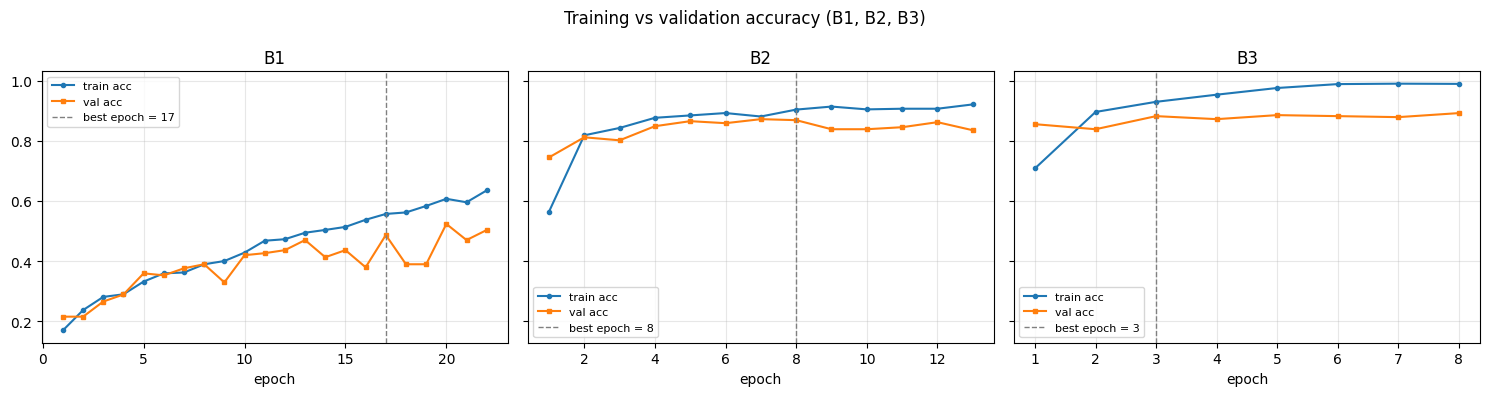

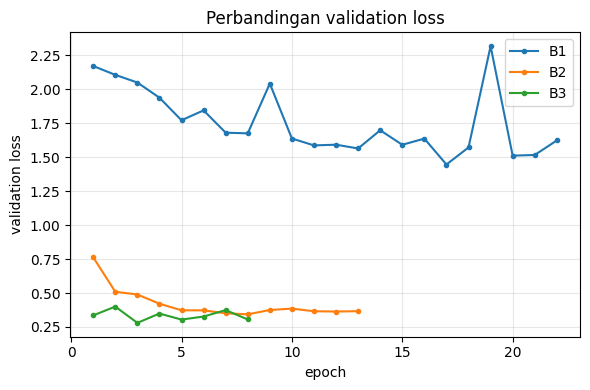

In [12]:
log_df = pd.DataFrame(EPOCH_LOG)

def plot_curves(codes, metric, fname, title):
    fig, axes = plt.subplots(1, len(codes), figsize=(5 * len(codes), 4), sharey=(metric == "acc"))
    for ax, c in zip(np.atleast_1d(axes), codes):
        h = log_df[log_df.experiment == c]
        ax.plot(h.epoch, h[f"train_{metric}"], "o-", ms=3, label=f"train {metric}")
        ax.plot(h.epoch, h[f"val_{metric}"],   "s-", ms=3, label=f"val {metric}")
        be = next(r["best_epoch"] for r in SUMMARY if r["experiment"] == c)
        ax.axvline(be, color="gray", ls="--", lw=1, label=f"best epoch = {be}")
        ax.set_title(c); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

plot_curves(["B1", "B2", "B3"], "loss", "C1_loss_curves_B1_B2_B3.png", "Training vs validation loss (B1, B2, B3)")
plot_curves(["B1", "B2", "B3"], "acc",  "C1_acc_curves_B1_B2_B3.png",  "Training vs validation accuracy (B1, B2, B3)")

# Overlay validation loss ketiga kondisi pada satu sumbu
plt.figure(figsize=(6, 4))
for c in ["B1", "B2", "B3"]:
    h = log_df[log_df.experiment == c]; plt.plot(h.epoch, h.val_loss, "o-", ms=3, label=c)
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.title("Perbandingan validation loss"); plt.grid(alpha=.3)
plt.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "C1_val_loss_overlay.png", dpi=150); plt.show()

## 8. C2 — Analisis B4 (augmentasi) dan B5 (trade-off efisiensi)

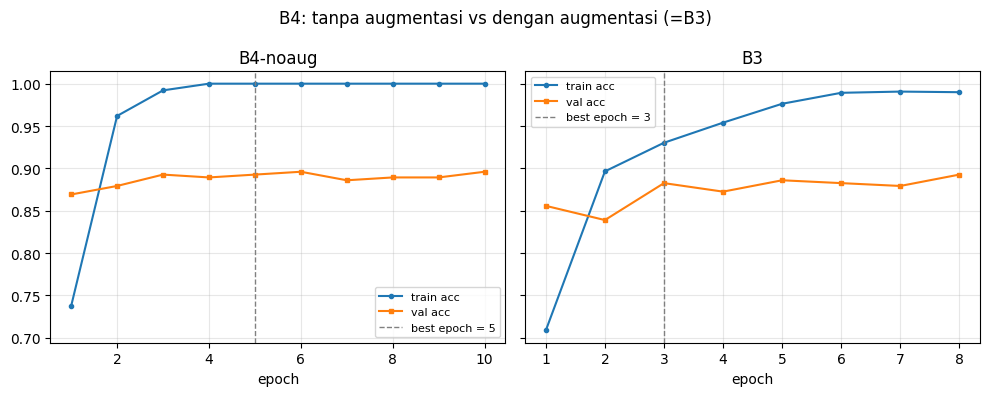

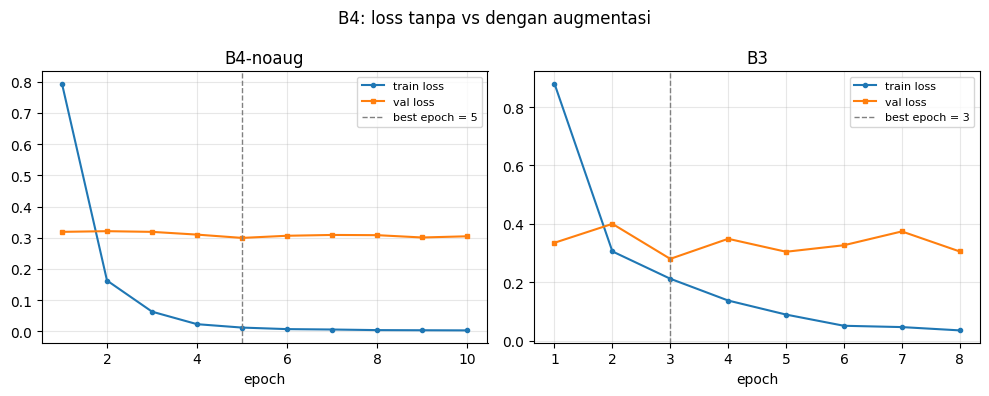

,train_acc_best,val_acc,gap_train_val_acc,test_acc,test_macro_f1
tanpa augmentasi,1.0000,0.8926,0.1074,0.9228,0.9213
dengan augmentasi (B3),0.9302,0.8826,0.0477,0.9161,0.9154


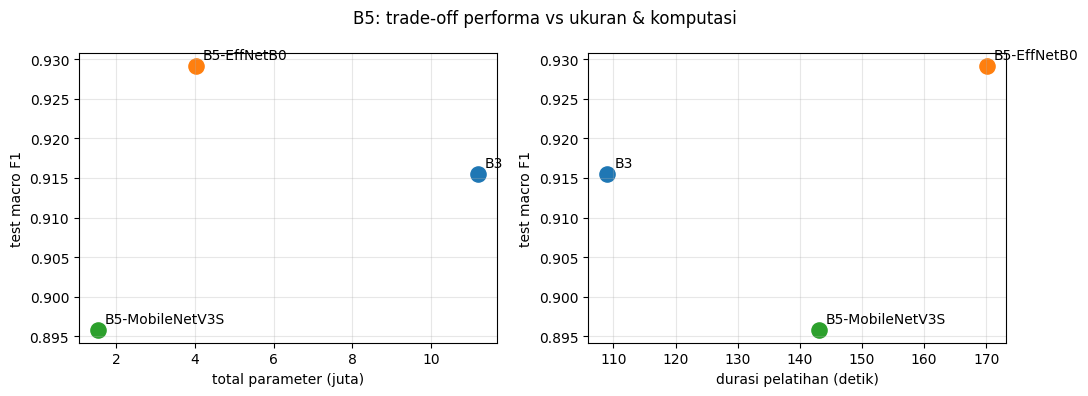

,experiment,trainable_params,total_params,best_epoch,train_time_s,latency_ms_per_img,test_acc,test_macro_f1
2,B3,8398858,11181642,3,109.0,0.9536,0.9161,0.9154
4,B5-EffNetB0,1142202,4020358,6,170.1,1.2172,0.9295,0.9291
5,B5-MobileNetV3S,1337586,1528106,5,143.1,0.3365,0.8960,0.8958


In [13]:
plot_curves(["B4-noaug", "B3"], "acc",  "C2_B4_acc_noaug_vs_aug.png",  "B4: tanpa augmentasi vs dengan augmentasi (=B3)")
plot_curves(["B4-noaug", "B3"], "loss", "C2_B4_loss_noaug_vs_aug.png", "B4: loss tanpa vs dengan augmentasi")

b4 = summary_df.set_index("experiment").loc[["B4-noaug", "B3"],
        ["train_acc_best", "val_acc", "gap_train_val_acc", "test_acc", "test_macro_f1"]]
b4.index = ["tanpa augmentasi", "dengan augmentasi (B3)"]; display(b4.round(4))

if RUN_B5:
    b5 = summary_df[summary_df.experiment.isin(["B3" if BEST_STRATEGY == "finetune" else "B2",
                                                "B5-EffNetB0", "B5-MobileNetV3S"])]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for _, r in b5.iterrows():
        ax[0].scatter(r.total_params / 1e6, r.test_macro_f1, s=120)
        ax[0].annotate(r.experiment, (r.total_params / 1e6, r.test_macro_f1), textcoords="offset points", xytext=(5, 5))
        ax[1].scatter(r.train_time_s, r.test_macro_f1, s=120)
        ax[1].annotate(r.experiment, (r.train_time_s, r.test_macro_f1), textcoords="offset points", xytext=(5, 5))
    ax[0].set_xlabel("total parameter (juta)"); ax[1].set_xlabel("durasi pelatihan (detik)")
    for a in ax: a.set_ylabel("test macro F1"); a.grid(alpha=.3)
    plt.suptitle("B5: trade-off performa vs ukuran & komputasi"); plt.tight_layout()
    plt.savefig(FIG_DIR / "C2_B5_tradeoff.png", dpi=150); plt.show()
    display(b5[["experiment", "trainable_params", "total_params", "best_epoch", "train_time_s",
                "latency_ms_per_img", "test_acc", "test_macro_f1"]].round(4))

## 9. C3 — Failure analysis pada model terbaik
Model terbaik dipilih berdasarkan **validation accuracy** (tie-break: val loss lebih rendah).
Ditampilkan 8 kesalahan test set dengan *confidence* tertinggi (kesalahan yang "paling yakin" paling informatif).

Model terbaik: B5-EffNetB0
                            precision    recall  f1-score   support

                Abyssinian     0.9655    0.9333    0.9492        30
                    Bengal     0.9677    1.0000    0.9836        30
                    Birman     0.9600    0.8000    0.8727        30
                   Ragdoll     0.8235    0.9333    0.8750        30
                   Siamese     0.9333    0.9333    0.9333        30
 American Pit Bull Terrier     0.8966    0.8667    0.8814        30
Staffordshire Bull Terrier     0.8667    0.9286    0.8966        28
                    Beagle     0.9091    1.0000    0.9524        30
              Basset Hound     1.0000    0.9000    0.9474        30
                   Samoyed     1.0000    1.0000    1.0000        30

                  accuracy                         0.9295       298
                 macro avg     0.9322    0.9295    0.9291       298
              weighted avg     0.9327    0.9295    0.9294       298



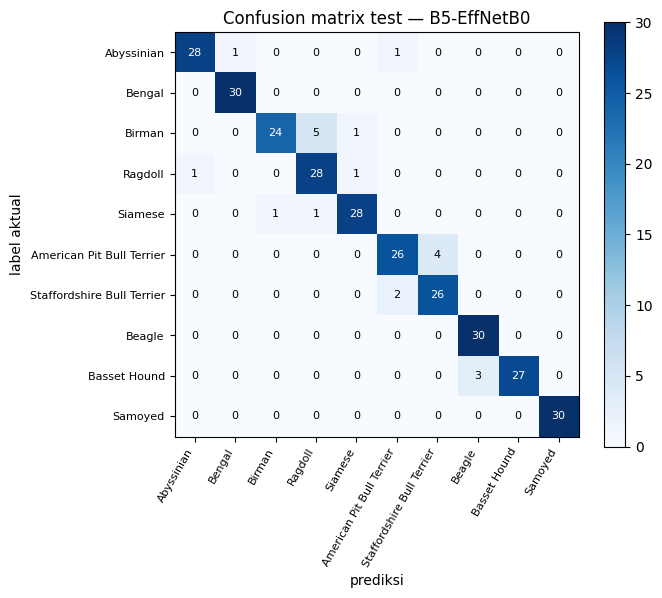

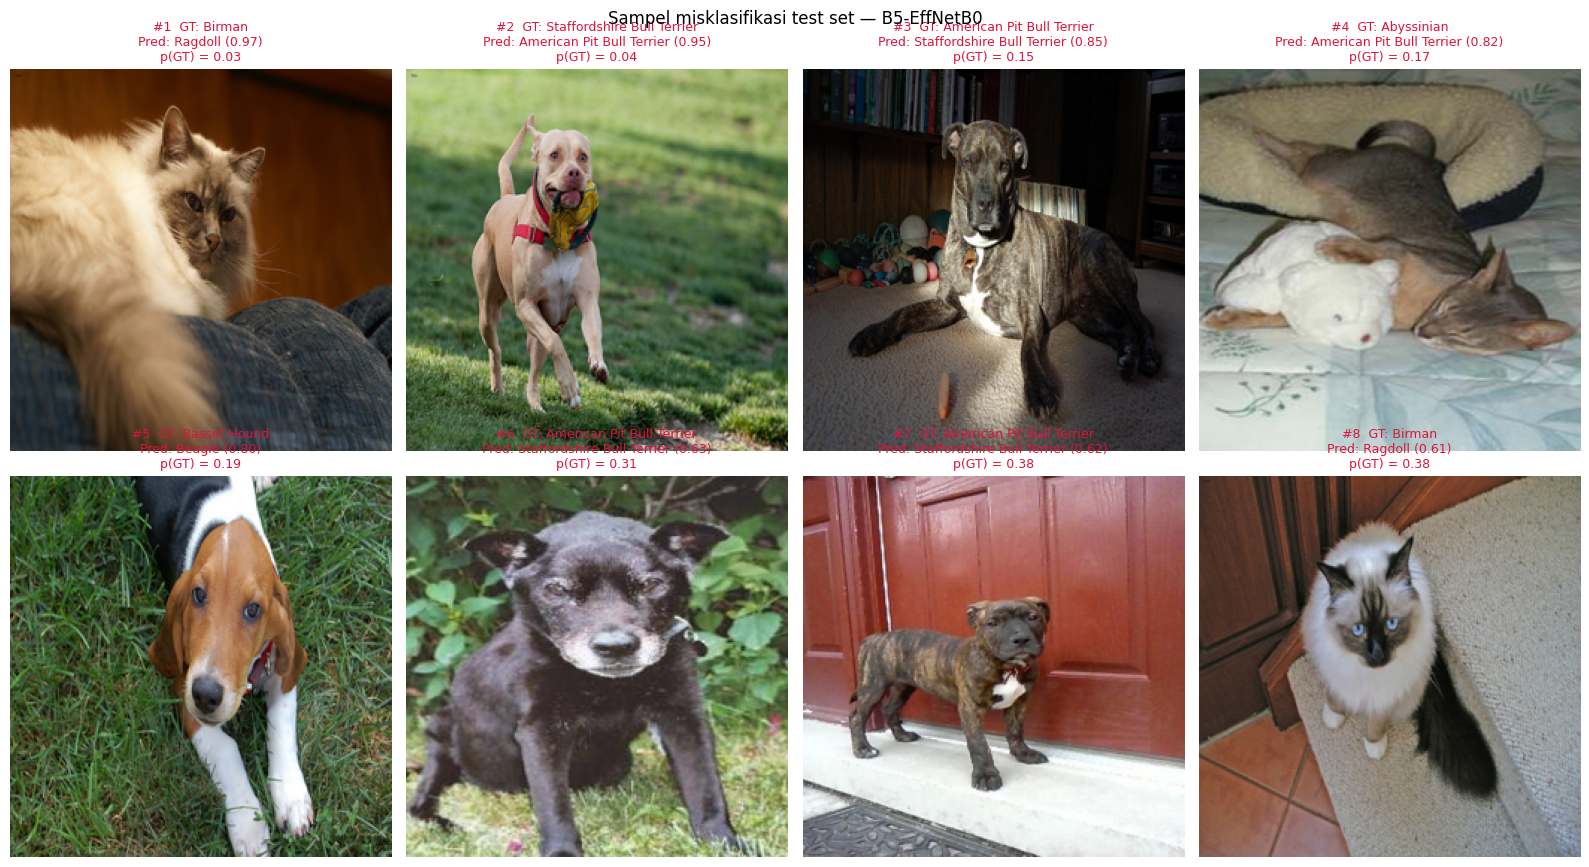

,test_idx,ground_truth,predicted,confidence,prob_true_class,second_choice,hypothesis
0,16,Birman,Ragdoll,0.968,0.032,Birman,<isi hipotesis Anda>
1,197,Staffordshire Bull Terrier,American Pit Bull Terrier,0.954,0.038,Staffordshire Bull Terrier,<isi hipotesis Anda>
2,146,American Pit Bull Terrier,Staffordshire Bull Terrier,0.853,0.145,American Pit Bull Terrier,<isi hipotesis Anda>
3,162,Abyssinian,American Pit Bull Terrier,0.818,0.170,Abyssinian,<isi hipotesis Anda>
4,41,Basset Hound,Beagle,0.800,0.187,Basset Hound,<isi hipotesis Anda>
5,241,American Pit Bull Terrier,Staffordshire Bull Terrier,0.627,0.314,American Pit Bull Terrier,<isi hipotesis Anda>
6,71,American Pit Bull Terrier,Staffordshire Bull Terrier,0.616,0.383,American Pit Bull Terrier,<isi hipotesis Anda>
7,216,Birman,Ragdoll,0.615,0.379,Birman,<isi hipotesis Anda>


In [14]:
BEST = (summary_df.sort_values(["val_acc", "val_loss"], ascending=[False, True]).iloc[0]["experiment"])
print("Model terbaik:", BEST)
y_true, y_pred, probs = PREDS[BEST]
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("prediksi"); ax.set_ylabel("label aktual"); ax.set_title(f"Confusion matrix test — {BEST}")
plt.colorbar(im); plt.tight_layout(); plt.savefig(FIG_DIR / "C3_confusion_matrix.png", dpi=150); plt.show()

test_paths = SPLITS["test"][0]
wrong = np.where(y_true != y_pred)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
rows = []
for i in wrong:
    top2 = np.argsort(-probs[i])[:2]
    rows.append({"test_idx": int(i), "path": test_paths[i], "ground_truth": CLASS_NAMES[y_true[i]],
                 "predicted": CLASS_NAMES[y_pred[i]], "confidence": float(probs[i, y_pred[i]]),
                 "prob_true_class": float(probs[i, y_true[i]]),
                 "second_choice": CLASS_NAMES[top2[1]], "hypothesis": "<isi hipotesis Anda>"})
mis_df = pd.DataFrame(rows); mis_df.to_csv(OUT_DIR / "misclassified_best_model.csv", index=False)

n = len(rows)
if n:
    cols = 4; r_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(r_, cols, figsize=(4 * cols, 4.4 * r_))
    for ax in np.atleast_1d(axes).flat: ax.axis("off")
    for k, (ax, row) in enumerate(zip(np.atleast_1d(axes).flat, rows), 1):
        ax.imshow(Image.open(row["path"]).convert("RGB").resize((256, 256)))
        ax.set_title(f"#{k}  GT: {row['ground_truth']}\nPred: {row['predicted']} ({row['confidence']:.2f})\n"
                     f"p(GT) = {row['prob_true_class']:.2f}", fontsize=9, color="crimson")
    plt.suptitle(f"Sampel misklasifikasi test set — {BEST}"); plt.tight_layout()
    plt.savefig(FIG_DIR / "C3_misclassified.png", dpi=150); plt.show()
display(mis_df.drop(columns=["path"]).round(3))

**Hipotesis penyebab kesalahan** — isi sendiri setelah melihat gambar di atas (jangan disalin dari mana pun):

| # | GT → Prediksi (conf.) | Hipotesis penyebab (ambiguitas ras / pose ekstrem / oklusi / pencahayaan / bias latar) |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |
| 4 | | |
| 5 | | |

## 10. C5 (Opsional) — Grad-CAM pada `layer4`: sebelum vs sesudah fine-tuning
*Sebelum* = model **B2** (bobot `layer4` masih persis bobot ImageNet; hanya head yang dilatih).
*Sesudah* = model **B3** (`layer4` telah di-fine-tune). Target Grad-CAM = kelas aktual.
Grad-CAM diimplementasikan manual dengan forward/backward hook (Selvaraju et al., 2017).

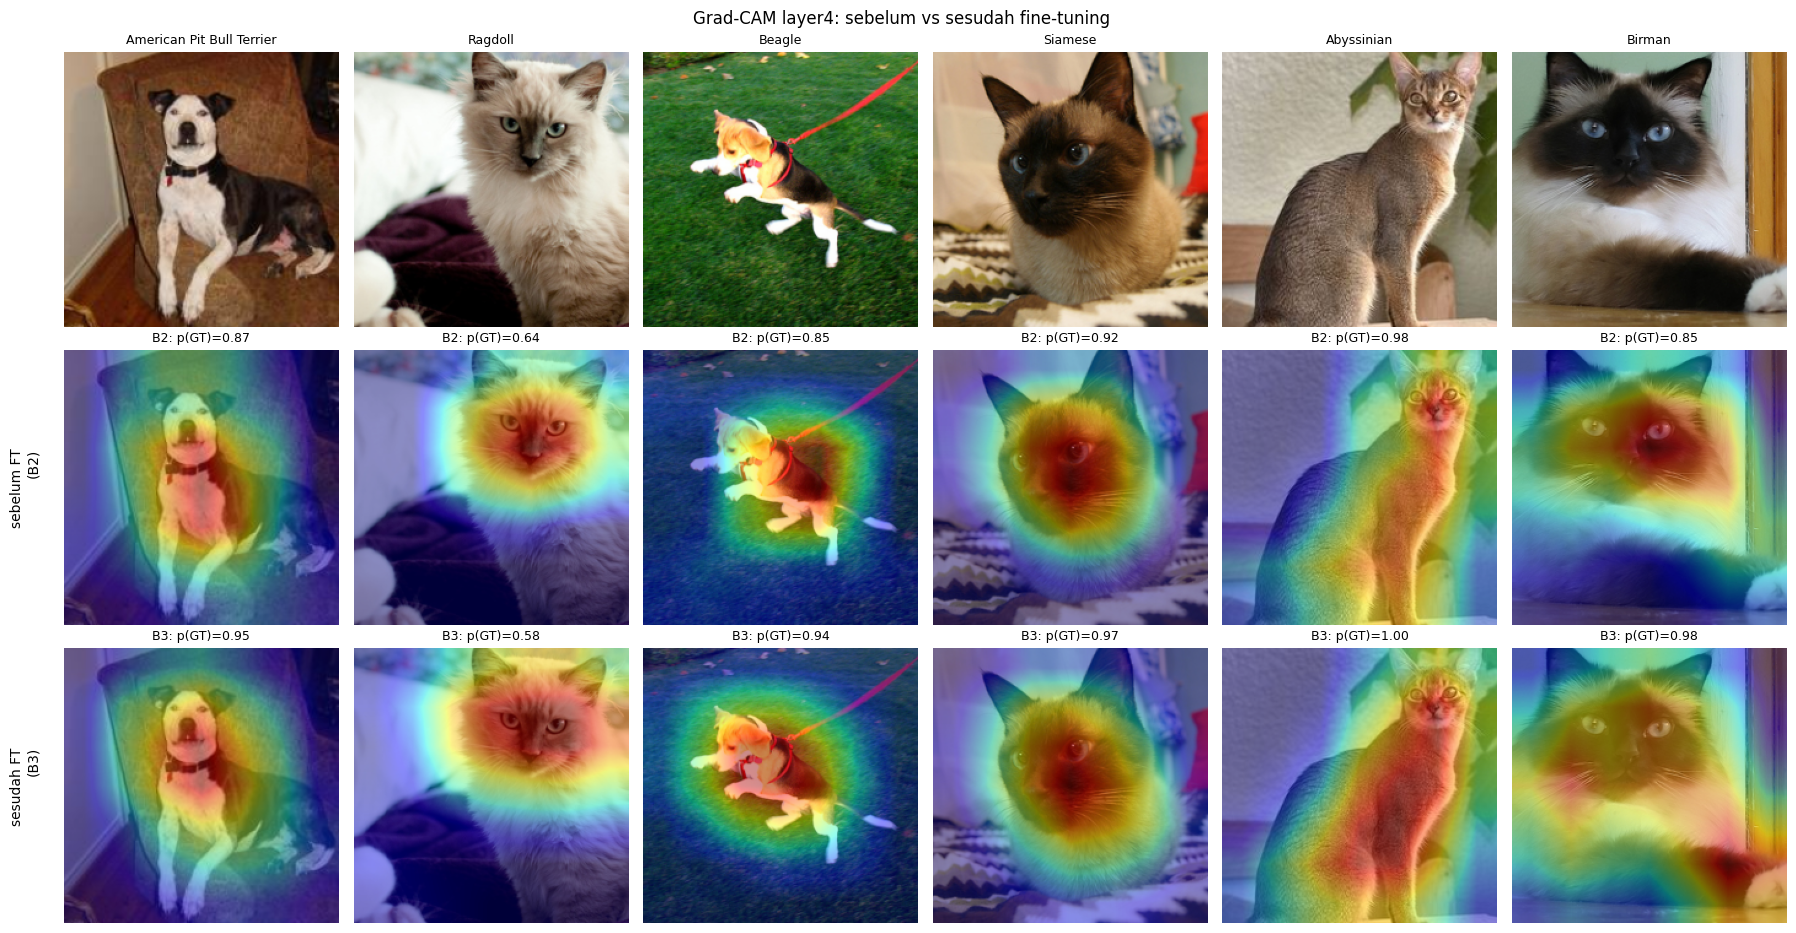

In [15]:
def grad_cam(model, x, target_layer, class_idx):
    model = copy.deepcopy(model).to(DEVICE).eval()
    for p in model.parameters(): p.requires_grad = True        # agar gradien mengalir walau layer beku
    layer = dict(model.named_modules())[target_layer]
    store = {}
    def fwd_hook(m, i, o):
        store["act"] = o
        o.register_hook(lambda g: store.__setitem__("grad", g))   # gradien terhadap aktivasi layer4
    h = layer.register_forward_hook(fwd_hook)
    out = model(x.unsqueeze(0).to(DEVICE))
    model.zero_grad(); out[0, class_idx].backward()
    h.remove()
    w = store["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), F.softmax(out, 1)[0, class_idx].item()

cam_ds = PetSubset(*SPLITS["test"], eval_tf)
rng = np.random.RandomState(SEED)
# ambil satu sampel dari 6 kelas berbeda
picked, seen = [], set()
for i in rng.permutation(len(cam_ds)):
    if cam_ds.labels[i] not in seen: picked.append(i); seen.add(cam_ds.labels[i])
    if len(picked) == 6: break

fig, axes = plt.subplots(3, len(picked), figsize=(3 * len(picked), 9.5))
for j, i in enumerate(picked):
    x, y = cam_ds[i]; img = denorm(x)
    axes[0, j].imshow(img); axes[0, j].set_title(CLASS_NAMES[y], fontsize=9)
    for r, code_ in [(1, "B2"), (2, "B3")]:
        cam, p = grad_cam(MODELS[code_], x, "layer4", y)
        axes[r, j].imshow(img); axes[r, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[r, j].set_title(f"{code_}: p(GT)={p:.2f}", fontsize=9)
for a in axes.flat: a.axis("off")
axes[1, 0].text(-20, 112, "sebelum FT\n(B2)", rotation=90, va="center", ha="right", fontsize=10)
axes[2, 0].text(-20, 112, "sesudah FT\n(B3)", rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle("Grad-CAM layer4: sebelum vs sesudah fine-tuning"); plt.tight_layout()
plt.savefig(FIG_DIR / "C5_gradcam_layer4.png", dpi=150); plt.show()

## 11. Simpan & arsipkan seluruh luaran

In [ ]:
save_logs()
pd.DataFrame(SUMMARY).to_csv(OUT_DIR / "summary.csv", index=False)
print("Berkas luaran:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file(): print(f"  {p}  ({p.stat().st_size/1024:.1f} KB)")
archive = shutil.make_archive("outputs_tugas05", "zip", OUT_DIR)
print("Arsip:", archive)
try:
    from google.colab import files 
    files.download(archive)
except ImportError:
    pass

Berkas luaran:
  outputs/figures/C1_acc_curves_B1_B2_B3.png  (82.5 KB)
  outputs/figures/C1_loss_curves_B1_B2_B3.png  (118.5 KB)
  outputs/figures/C1_val_loss_overlay.png  (52.9 KB)
  outputs/figures/C2_B4_acc_noaug_vs_aug.png  (70.7 KB)
  outputs/figures/C2_B4_loss_noaug_vs_aug.png  (74.6 KB)
  outputs/figures/C2_B5_tradeoff.png  (57.4 KB)
  outputs/figures/C3_confusion_matrix.png  (94.4 KB)
  outputs/figures/C3_misclassified.png  (3394.8 KB)
  outputs/figures/C5_gradcam_layer4.png  (3865.6 KB)
  outputs/figures/augmented_samples.png  (1255.0 KB)
  outputs/metrics_per_epoch.csv  (10.4 KB)
  outputs/misclassified_best_model.csv  (1.4 KB)
  outputs/results.json  (31.4 KB)
  outputs/split_manifest.csv  (130.5 KB)
  outputs/summary.csv  (1.6 KB)
  outputs/summary_table.md  (2.1 KB)
Arsip: /content/outputs_tugas05.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>